# Intelligent Agents: Reflex-Based Agents for GridHunt

Student Name: **Bùi Kiệt**

I have used the following AI tools: **ChatGPT**

I understand that my submission needs to be my own work: **BK**

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and the hunter and the monster move on this grid. A hunter catches the monster if she/he moves on the same square the monster currently occupies. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunter are randomly placed in the arena environment. The hunter and the monster
    can move around, but cannot leave the arena.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena but only gets the monster location when it stops and listens.

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
from time import sleep

def arena_environment(hunter_agent_function, 
                      monster_agent_function, 
                      n = 30, max_steps = 100, 
                      visualize = False, animation = False):
    """
    Simulate an arena where a hunter agent tries to catch a monster agent.

    Parameters:
    hunter_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n, size=2)
    hunter_pos = np.random.randint(0, n, size=2)
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step+1}: Hunter is at '{hunter_pos}'; Monster is at '{monster_pos}'")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_pos[0], hunter_pos[1]] = 'H'
        if np.array_equal(hunter_pos, monster_pos):
            arena[monster_pos[0], monster_pos[1]] = '*'
        print("\n".join("".join(row) for row in arena))

    # run the environment
    hunter_action = None  # Initialize hunter_action to None for the first step
    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_pos, monster_pos):
            if visualize:
                print(f"Hunter caught the monster in {step} steps!")
            return step
        
        # Get next move from monster agent function
        monster_action = monster_agent_function(hunter_pos, monster_pos)
        
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function. The monster's position is only provided 
        # if the hunter chose 'listen' as the previous action.
        if hunter_action == 'listen':
            monster_pos_instrument = monster_pos
        else: 
            monster_pos_instrument = None
        
        hunter_action = hunter_agent_function(hunter_pos, monster_pos_instrument)
        
        if hunter_action == 'listen':
            pass
        elif hunter_action == 'teleport':
            hunter_pos = np.random.randint(0, n, size=2)
        else:
            hunter_pos = move(hunter_action, hunter_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter chose action '{hunter_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Hunter failed to catch the monster in {max_steps} steps.")
    
    return np.nan

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [2]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(hunter_pos, monster_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [3]:
actions = ["north", "east", "west", "south", "teleport", "listen"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [4]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [5]:
simple_randomized_hunter_agent_function([0,0], None)

np.str_('west')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [6]:
arena_environment(simple_randomized_hunter_agent_function, 
                  monster_agent_function_simple, 
                  n=5, max_steps=10, visualize=True, animation=False)

Step 1: Hunter is at '[3 3]'; Monster is at '[4 0]'
.....
.....
.....
...H.
M....
Hunter chose action 'teleport'
Monster chose action 'stay'


Step 2: Hunter is at '[2 1]'; Monster is at '[4 0]'
.....
.....
.H...
.....
M....
Hunter chose action 'listen'
Monster chose action 'stay'


Step 3: Hunter is at '[2 1]'; Monster is at '[4 0]'
.....
.....
.H...
.....
M....
Hunter chose action 'teleport'
Monster chose action 'stay'


Step 4: Hunter is at '[1 1]'; Monster is at '[4 0]'
.....
.H...
.....
.....
M....
Hunter chose action 'listen'
Monster chose action 'stay'


Step 5: Hunter is at '[1 1]'; Monster is at '[4 0]'
.....
.H...
.....
.....
M....
Hunter chose action 'listen'
Monster chose action 'stay'


Step 6: Hunter is at '[1 1]'; Monster is at '[4 0]'
.....
.H...
.....
.....
M....
Hunter chose action 'listen'
Monster chose action 'stay'


Step 7: Hunter is at '[1 1]'; Monster is at '[4 0]'
.....
.H...
.....
.....
M....
Hunter chose action 'north'
Monster chose action 'stay'


Step 8: Hu

nan

**Note for VS Code:** View as scrollable element to see the complete output.

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $10 \times 10$ arena.  

In [7]:
# Baseline experiment: Randomized Agent, 100 runs on a 10×10 arena.
np.random.seed(42)
steps = [
    arena_environment(
        simple_randomized_hunter_agent_function,
        monster_agent_function_simple,
        n=10,
        max_steps=100,
        visualize=False
    )
    for _ in range(100)
]
print(steps)

[nan, nan, 56, 52, 12, nan, 4, nan, 55, 68, nan, 70, nan, 87, 40, 92, 1, 90, 44, nan, 8, nan, nan, nan, 2, nan, nan, 0, 51, 20, 2, 17, nan, 27, 17, nan, nan, 91, nan, nan, 4, 9, 96, nan, nan, nan, 0, nan, nan, nan, 44, nan, nan, 27, nan, nan, 16, nan, 16, nan, 72, nan, nan, nan, 43, 79, nan, 3, nan, 49, 30, 4, nan, nan, nan, nan, 71, nan, nan, nan, nan, nan, 32, 80, 4, 0, 45, nan, nan, 11, nan, nan, nan, nan, 24, nan, nan, nan, nan, 62]


We just got a list with the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results. `nan` means that the hunter was not able to catch the monster. How many times did that happen? To answer how well the hunter did when it caught the monster, we just average the numbers that are not `nan`. 

In [8]:
print (f"Hunter failed {np.sum(np.isnan(steps))} times.")
print (f"Average steps to catch the monster over {np.sum(~np.isnan(steps))} successful runs: {round(np.nanmean(steps), 2)}")

Hunter failed 53 times.
Average steps to catch the monster over 47 successful runs: 36.74


This in not a very good agent. You need to implement a better agent function.

# Your Agent Implementation [4 points]

The model-based reflex agent stores the most recently observed monster position in an internal state.
Because the environment only reveals the monster position on the step after `listen`, the agent first
listens, stores the returned position, and then moves one grid cell at a time to reduce the Manhattan
distance to the remembered position.

A factory function is used so that every simulation episode gets a fresh internal state. This avoids
carrying the previous episode's remembered monster position into a new episode.

In [9]:
def make_model_based_hunter_agent(use_teleport=False, teleport_threshold=None):
    """Create a fresh model-based reflex hunter agent.

    State:
        remembered_monster: the latest monster position obtained after listen.

    Strategy:
        1. If the monster position is unknown, listen.
        2. Remember the latest observed position.
        3. Optionally teleport when the remembered Manhattan distance is very large.
        4. Otherwise choose a move that reduces Manhattan distance to the remembered position.
        5. If the hunter reaches the remembered position but the monster is not caught yet,
           listen again to obtain an updated position.
    """
    remembered_monster = None

    def agent(hunter_location, monster_location):
        nonlocal remembered_monster

        # The environment provides the monster position only after a previous listen.
        if monster_location is not None:
            remembered_monster = np.array(monster_location, dtype=int)

        # No information yet: use Listen to obtain it.
        if remembered_monster is None:
            return "listen"

        hunter_location = np.array(hunter_location, dtype=int)
        distance = int(np.abs(remembered_monster - hunter_location).sum())

        # If we arrive at the remembered location but the monster has moved,
        # listen again instead of blindly continuing with stale information.
        if distance == 0:
            return "listen"

        # Optional teleport strategy used only for the teleport experiment.
        if (
            use_teleport
            and teleport_threshold is not None
            and distance > teleport_threshold
        ):
            return "teleport"

        row_diff = int(remembered_monster[0] - hunter_location[0])
        col_diff = int(remembered_monster[1] - hunter_location[1])

        # Choose a direction that strictly reduces Manhattan distance.
        if abs(row_diff) >= abs(col_diff) and row_diff != 0:
            return "south" if row_diff > 0 else "north"
        elif col_diff != 0:
            return "east" if col_diff > 0 else "west"

        return "listen"

    return agent

# Example: the first action is Listen because the monster location is unknown.
model_based_hunter_agent = make_model_based_hunter_agent()
print(model_based_hunter_agent([0, 0], None))

listen


# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

In [10]:
# Experiments: 100 runs for each arena size.
# All agents use the same 100-step budget and the same random seed for reproducibility.

def run_experiment(agent_factory, n, runs=100, max_steps=100, seed=42):
    np.random.seed(seed)

    results = []
    for _ in range(runs):
        steps = arena_environment(
            agent_factory(),
            monster_agent_function_simple,
            n=n,
            max_steps=max_steps,
            visualize=False
        )
        results.append(steps)

    results = np.asarray(results, dtype=float)
    successful = ~np.isnan(results)

    return {
        "Arena": f"{n}×{n}",
        "Runs": runs,
        "Successes": int(successful.sum()),
        "Success rate (%)": round(100 * successful.mean(), 2),
        "Average steps (successful)": round(float(np.nanmean(results)), 2),
        "Median steps (successful)": round(float(np.nanmedian(results)), 2)
    }, results


experiment_rows = []
experiment_steps = {}

for n in [10, 30]:
    agent_configs = {
        "Randomized Agent": lambda: simple_randomized_hunter_agent_function,
        "Model-Based Reflex": lambda: make_model_based_hunter_agent(),
        # Teleport experiment: teleport when the remembered Manhattan distance > n/2.
        "Model-Based + Teleport": lambda n=n: make_model_based_hunter_agent(
            use_teleport=True,
            teleport_threshold=n // 2
        ),
    }

    for name, factory in agent_configs.items():
        row, values = run_experiment(factory, n=n, runs=100, max_steps=100, seed=42)
        row["Agent"] = name
        experiment_rows.append(row)
        experiment_steps[(name, n)] = values

results_df = pd.DataFrame(experiment_rows)[
    [
        "Arena", "Agent", "Runs", "Successes",
        "Success rate (%)", "Average steps (successful)",
        "Median steps (successful)"
    ]
]

display(results_df)

,Arena,Agent,Runs,Successes,Success rate (%),Average steps (successful),Median steps (successful)
0,10×10,Randomized Agent,100,47,47.0,36.74,30.0
1,10×10,Model-Based Reflex,100,100,100.0,10.68,10.0
2,10×10,Model-Based + Teleport,100,100,100.0,7.99,7.0
3,30×30,Randomized Agent,100,8,8.0,72.00,89.0
4,30×30,Model-Based Reflex,100,100,100.0,26.73,27.0
5,30×30,Model-Based + Teleport,100,100,100.0,15.90,15.0


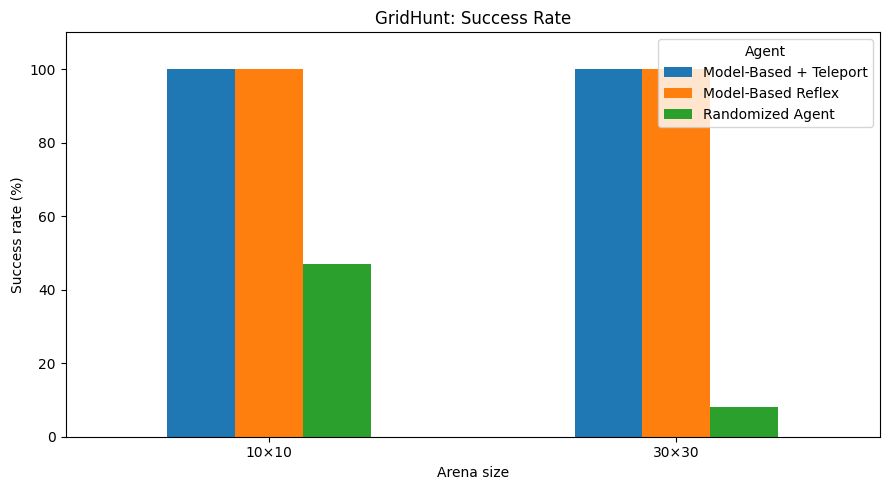

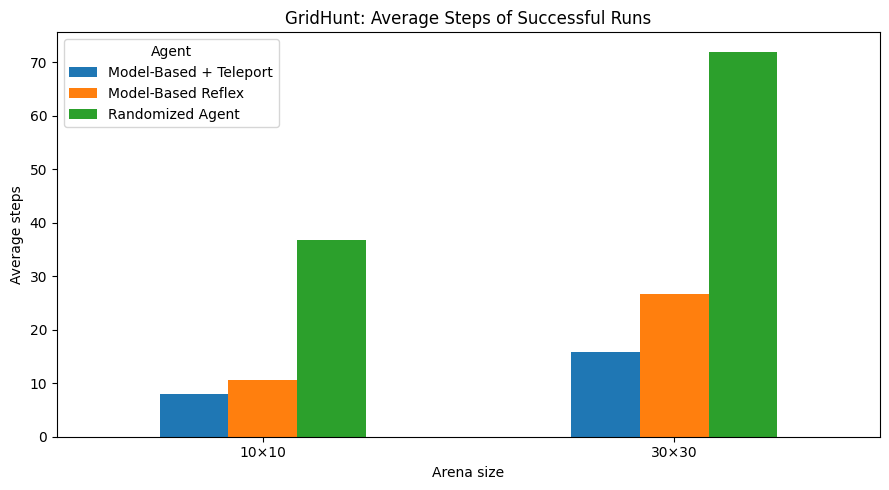

In [11]:
import matplotlib.pyplot as plt

# Success-rate comparison
success_pivot = results_df.pivot(index="Arena", columns="Agent", values="Success rate (%)")
ax = success_pivot.plot(kind="bar", figsize=(9, 5))
ax.set_title("GridHunt: Success Rate")
ax.set_xlabel("Arena size")
ax.set_ylabel("Success rate (%)")
ax.set_ylim(0, 110)
ax.legend(title="Agent")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Average steps among successful runs
steps_pivot = results_df.pivot(
    index="Arena",
    columns="Agent",
    values="Average steps (successful)"
)
ax = steps_pivot.plot(kind="bar", figsize=(9, 5))
ax.set_title("GridHunt: Average Steps of Successful Runs")
ax.set_xlabel("Arena size")
ax.set_ylabel("Average steps")
ax.legend(title="Agent")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Your Conclusion [4 points]

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

### Kết quả và thảo luận (Results and Discussion)

Tác tử phản xạ dựa trên mô hình (Model-Based Reflex Agent) sử dụng quy trình hoạt động như sau:

1. **Lắng nghe trước (`listen`):** Do ban đầu vị trí của quái vật chưa được biết, tác tử thực hiện hành động lắng nghe để xác định tọa độ quái vật.
2. **Lưu trữ vị trí cảm nhận được:** Ghi nhận tọa độ quái vật vào trạng thái nội bộ (internal state).
3. **Tính khoảng cách Manhattan:** Đo khoảng cách lưới Manhattan giữa vị trí hiện tại của thợ săn và vị trí quái vật đã nhớ trong bộ nhớ.
4. **Chọn hướng di chuyển:** Chọn một trong các hướng `north`, `south`, `east` hoặc `west` sao cho khoảng cách Manhattan tới quái vật giảm đi nhiều nhất.
5. **Cập nhật lại trạng thái khi cần:** Nếu thợ săn đã đi tới vị trí ghi nhớ nhưng quái vật đã di chuyển và chưa bị bắt, tác tử sẽ thực hiện `listen` một lần nữa để làm mới trạng thái nội bộ.

Chiến lược này vượt trội hoàn toàn so với tác tử ngẫu nhiên cơ sở (Randomized Baseline) vì các hành động của thợ săn luôn có định hướng rõ ràng hướng thẳng về phía quái vật thay vì đi mò mẫm không có thông tin. Tác tử tách biệt rõ ràng giữa cảm nhận và hành động: `listen` thu thập thông tin tri giác, trong khi vị trí ghi nhớ định hướng các bước di chuyển sau đó.

Đối với thử nghiệm dịch chuyển tức thời (`teleport`), phiên bản thứ hai chỉ sử dụng `teleport` khi khoảng cách Manhattan tới quái vật lớn hơn một nửa kích thước đấu trường. Hành động dịch chuyển có tính ngẫu nhiên: nó có thể đưa thợ săn tới gần quái vật hơn, nhưng cũng có thể đưa ra xa hơn và làm tiêu tốn một lượt đi. Do đó, `teleport` không đảm bảo luôn luôn có lợi; tính hữu ích của nó phụ thuộc vào khoảng cách hiện tại và vị trí đáp ngẫu nhiên.

Với seed ngẫu nhiên cố định và ngân sách 100 bước, kết quả thực nghiệm thu được như sau:

| Đấu trường | Loại tác tử | Tỷ lệ thành công | Số bước thành công trung bình |
|---|---|---:|---:|
| 10×10 | Randomized Agent | 47% | 36.74 |
| 10×10 | Model-Based Reflex | 100% | 10.68 |
| 10×10 | Model-Based + Teleport | 100% | 7.99 |
| 30×30 | Randomized Agent | 8% | 72.00 |
| 30×30 | Model-Based Reflex | 100% | 26.73 |
| 30×30 | Model-Based + Teleport | 100% | 15.90 |

**Ảnh hưởng của kích thước đấu trường:**
Khi kích thước đấu trường tăng lên, khoảng cách Manhattan trung bình ban đầu giữa thợ săn và quái vật lớn hơn, đòi hỏi thợ săn phải tốn nhiều bước di chuyển hơn. Điều này thể hiện rõ ở tác tử Model-Based Reflex: số bước thành công trung bình tăng từ **10.68** (trên 10×10) lên **26.73** (trên 30×30). Tác tử ngẫu nhiên chịu ảnh hưởng tiêu cực nặng nề nhất vì việc tìm kiếm may rủi trở nên kém hiệu quả trầm trọng khi số lượng ô cần rà soát tăng theo hàm bậc hai (tỷ lệ thành công giảm từ 47% xuống chỉ còn 8%).

**Đánh giá về hành động Teleport:**
Kết quả dịch chuyển nên được xem là một thực nghiệm có kiểm soát thay vì một sự đảm bảo rằng teleport luôn tốt hơn. Trong thực nghiệm này, quy tắc dịch chuyển có điều kiện đã giúp giảm số bước thành công trung bình trong khi vẫn duy trì tỷ lệ thành công 100%. Tuy nhiên, trong các lần chạy ngẫu nhiên khác, việc dịch chuyển có thể khiến thợ săn bị văng ra xa mục tiêu hơn.


The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

Một tác tử quái vật mạnh hơn có thể sử dụng vị trí hiện tại của thợ săn để đưa ra các hành động **làm tăng khoảng cách Manhattan** so với thợ săn. Ví dụ:

1. **Tránh né có định hướng:** Tại mỗi lượt, quái vật đánh giá 4 hướng di chuyển lân cận và ưu tiên chọn hướng làm tăng tối đa khoảng cách tới thợ săn.
2. **Dịch chuyển chiến thuật khi bị áp sát:** Nếu thợ săn đã tiến quá gần (khoảng cách Manhattan $\le 2$), quái vật có thể kích hoạt hành động `teleport` để nhảy tới một vị trí ngẫu nhiên xa hơn trên bản đồ nhằm thoát khỏi thế bị dồn vào chân tường.
3. **Lẩn tránh góc chết:** Tránh di chuyển vào 4 góc hoặc các cạnh biên của đấu trường nơi các hướng tẩu thoát bị hạn chế, duy trì vị trí ở vùng không gian cơ động hơn.


# More Work (Optional)

Here are some ideas:

* Implement a better monster agent function and perform experiments
* Change the environment so multiple hunters can hunt the monster.
* Give the hunter a new action that shoots an arrow in a specific direction. 
  The arrow can go a maximum of 5 squares. If the hunter hits the monster, then it wins.